In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

## Phase 1: Data and preprocessing
We load the uploaded `Mall_Customers_dataset.xlsx` dataset, inspect its structure, and prepare the continuous features for clustering.

In [ ]:
import pandas as pd

df = pd.read_excel('/content/Mall_Customers_dataset.xlsx')

print("Original Columns:", df.columns.tolist())

rename_dict = {}
for col in df.columns:
    if 'age' in col.lower():
        rename_dict[col] = 'Age'
    elif 'income' in col.lower():
        rename_dict[col] = 'Income'
    elif 'spending' in col.lower() or 'score' in col.lower():
        rename_dict[col] = 'Spending'

df = df.rename(columns=rename_dict)

display(df.head())

Original Columns: ['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


,CustomerID,Gender,Age,Income,Spending
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
features = ["Age", "Income", "Spending"]
print("Dataset Shape:", df.shape)
print("\nMissing values per column:")
print(df[features].isna().sum())
print(f"\n{df[features].duplicated().sum()} duplicate rows based on clustering features")
df[features].describe()

Dataset Shape: (200, 5)

Missing values per column:
Age         0
Income      0
Spending    0
dtype: int64

0 duplicate rows based on clustering features


,Age,Income,Spending
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


### Why scale?
K-Means uses straight-line (Euclidean) distance. Income spans a much bigger range than Age, so without scaling
Income would dominate the distance. `StandardScaler` converts each column to mean 0 and standard deviation 1.

In [ ]:
features = ["Age", "Income", "Spending"]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled Means:", X_scaled.mean(axis=0).round(2))
print("Scaled Stds:", X_scaled.std(axis=0).round(2))

Scaled Means: [-0. -0. -0.]
Scaled Stds: [1. 1. 1.]


## Phase 2: Choosing K
**Elbow:** inertia = sum of squared distances from each point to its centroid. It always falls as K rises, so we look for the bend
where adding clusters stops helping much.

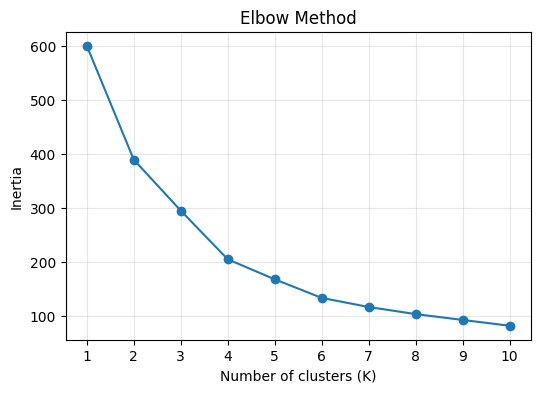

In [ ]:
k_range = range(1, 11)
inertias = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(k_range, inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(k_range)
plt.grid(alpha=0.3)
plt.show()

**Silhouette score** runs from -1 to 1 and measures how close a point is to its own cluster compared with the nearest other cluster.
Higher is better. It needs K ≥ 2.

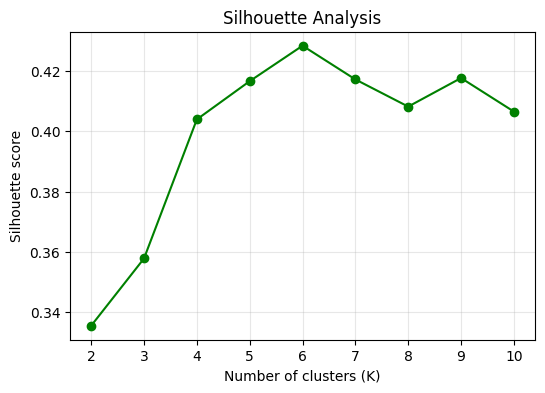

K with highest silhouette: 6


In [ ]:
sil_scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    sil_scores.append(silhouette_score(X_scaled, labels))

plt.figure(figsize=(6, 4))
plt.plot(range(2, 11), sil_scores, marker="o", color="green")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Analysis")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.show()

best_k = range(2, 11)[int(np.argmax(sil_scores))]
print("K with highest silhouette:", best_k)

## Phase 3: Final model and centroids
`random_state` fixes the random start so results repeat every run.

In [ ]:
K = 5
k_means = KMeans(n_clusters=K, random_state=42, n_init=10)
df["Cluster"] = k_means.fit_predict(X_scaled)

# Centroids are in SCALED units; convert back to real units to interpret them
centroids_scaled = k_means.cluster_centers_
centroids = scaler.inverse_transform(centroids_scaled)
centroid_df = pd.DataFrame(centroids, columns=features).round(1)
centroid_df["Size"] = df["Cluster"].value_counts().sort_index().values
centroid_df

,Age,Income,Spending,Size
0,46.2,26.8,18.3,20
1,25.2,41.1,62.2,54
2,32.9,86.1,81.5,40
3,39.9,86.1,19.4,39
4,55.6,54.4,48.9,47


## Phase 4: Visualization

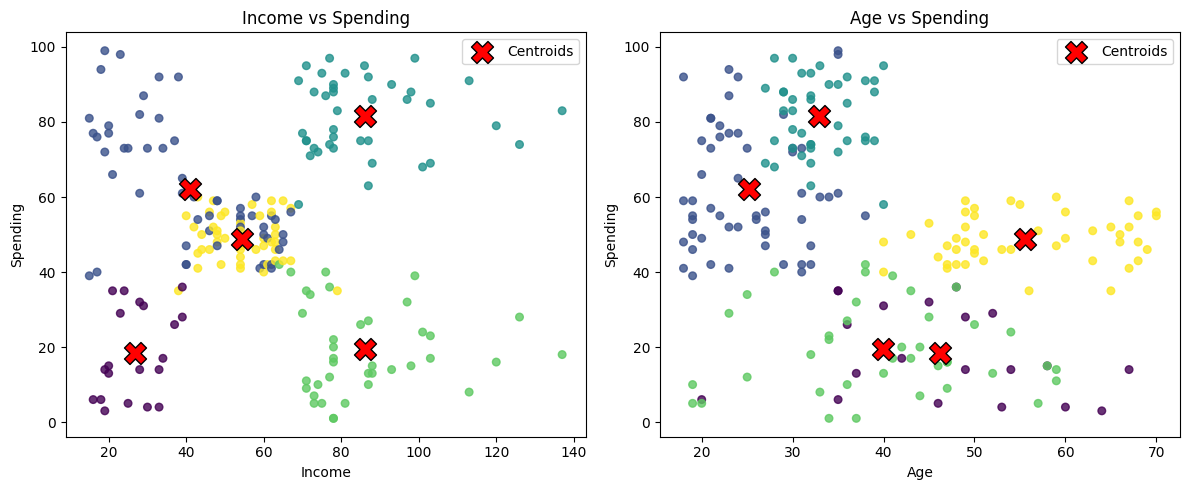

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
pairs = [("Income", "Spending"), ("Age", "Spending")]

for ax, (xf, yf) in zip(axes, pairs):
    sc = ax.scatter(df[xf], df[yf], c=df["Cluster"], cmap="viridis", s=30, alpha=0.8)
    # plot centroids using real-unit coordinates
    ax.scatter(centroid_df[xf], centroid_df[yf], c="red", marker="X",
               s=250, edgecolor="black", label="Centroids")
    ax.set_xlabel(xf)
    ax.set_ylabel(yf)
    ax.set_title(f"{xf} vs {yf}")
    ax.legend()
plt.tight_layout()
plt.show()

## Cluster Descriptions

Based on the centroid values calculated from the Mall Customers dataset, we can profile each customer segment in plain English:

* **Cluster 0 (Sensible / Budget Buyers):** Represents older individuals (average age of 46) with lower annual income (average of 27k) and low spending scores. They are cautious and price-sensitive spenders.

* **Cluster 1 (Carefree / Active Youth):** Represents young customers (average age of 25) with moderate annual incomes (around 41k) but very high spending scores. These represent highly active, trend-driven shoppers.

* **Cluster 2 (Target / Luxury Shoppers):** Represents younger to middle-aged adults (average age of 33) with high annual incomes (around 86k) and high spending scores. This is the prime target demographic for premium products and campaigns.

* **Cluster 3 (Affluent Savers):** Represents middle-aged customers (average age of 40) with high annual incomes (around 86k) but very low spending scores. They have high purchasing power but are conservative shoppers.

* **Cluster 4 (Steady / Average Consumers):** Represents older individuals (average age of 56) with moderate annual incomes (around 54k) and moderate spending scores. This is the steady, standard demographic that shops regularly but moderately.